In [20]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [21]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tree_propagation.consts import DEFAULT_RANDOM_SEED
from tree_propagation.environment import EnvironmentState
from tree_propagation.metrics import evaluate_seed_shadow
from tree_propagation.simulation import SeedDispersalSimulation, SeedDispersalSimulationParams
from tree_propagation.species_config import load_species_configs_from_csv
from tree_propagation.visualization.matplot import plot_simulated_seed_shadow_and_distance_histogram
from tree_propagation.wind_config import DEFAULT_WIND_ROSE


In [22]:
logging.basicConfig(level=logging.INFO)

In [23]:
rng = np.random.default_rng(DEFAULT_RANDOM_SEED)
species_config = load_species_configs_from_csv("./data/tree_species_config.csv")
species_config


{'Ahorn': SpeciesConfig(species_name='Ahorn', dispersal_type=<DispersalType.WIND: 'wind'>, wind_spreading_factor=0.9, mean_dispersal_distance=None, fecundity=2.0, maturity_age=20, years_per_height_class=12, maximal_height_class=8, mean_life_span=300, shade_tolerance=0.8),
 'Akazie': SpeciesConfig(species_name='Akazie', dispersal_type=<DispersalType.GRAVITY: 'gravity'>, wind_spreading_factor=None, mean_dispersal_distance=10.0, fecundity=3.0, maturity_age=6, years_per_height_class=7, maximal_height_class=7, mean_life_span=100, shade_tolerance=0.18),
 'Buche': SpeciesConfig(species_name='Buche', dispersal_type=<DispersalType.ANIMAL: 'animal'>, wind_spreading_factor=None, mean_dispersal_distance=30.0, fecundity=1.2, maturity_age=30, years_per_height_class=18, maximal_height_class=8, mean_life_span=400, shade_tolerance=0.89),
 'Esche': SpeciesConfig(species_name='Esche', dispersal_type=<DispersalType.WIND: 'wind'>, wind_spreading_factor=0.7, mean_dispersal_distance=None, fecundity=2.4, matu

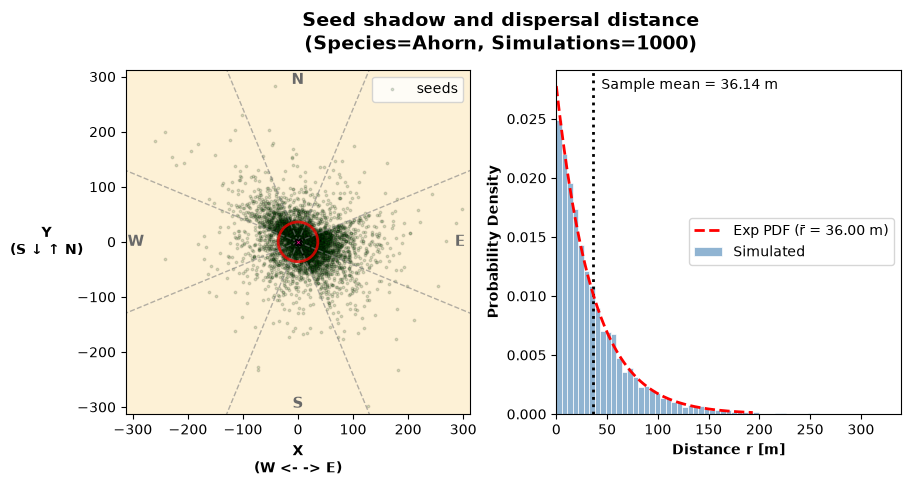

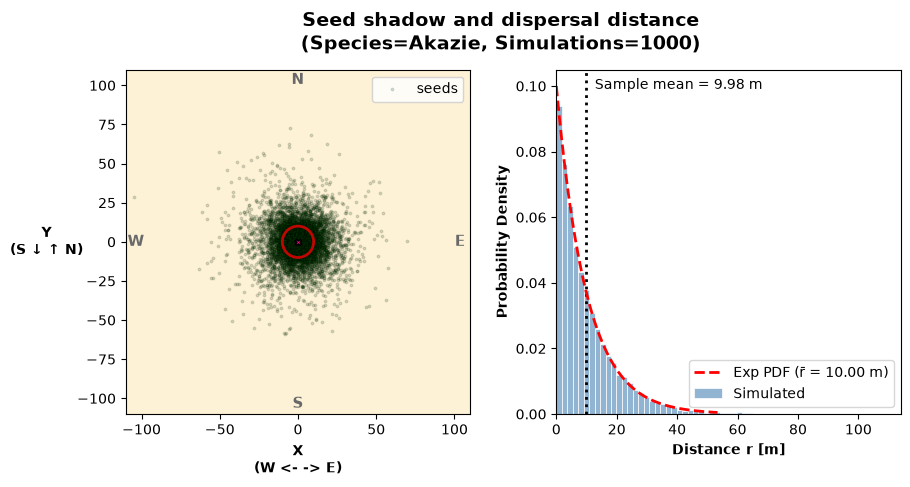

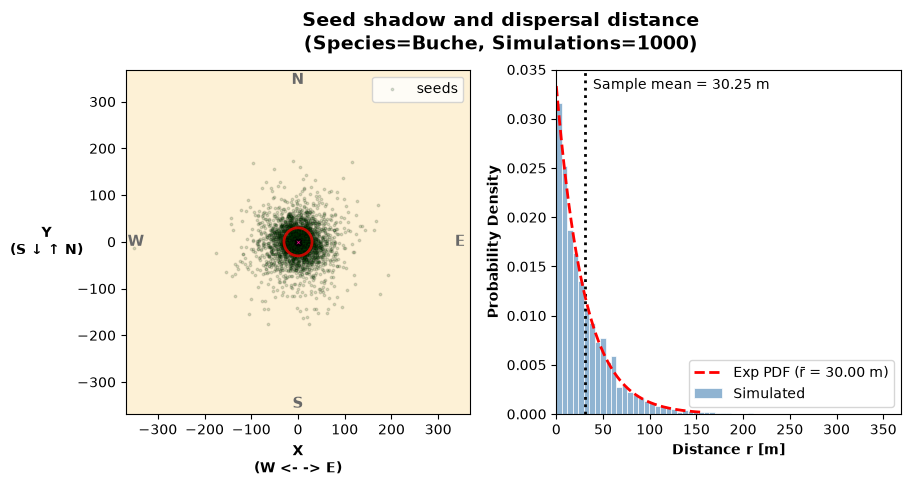

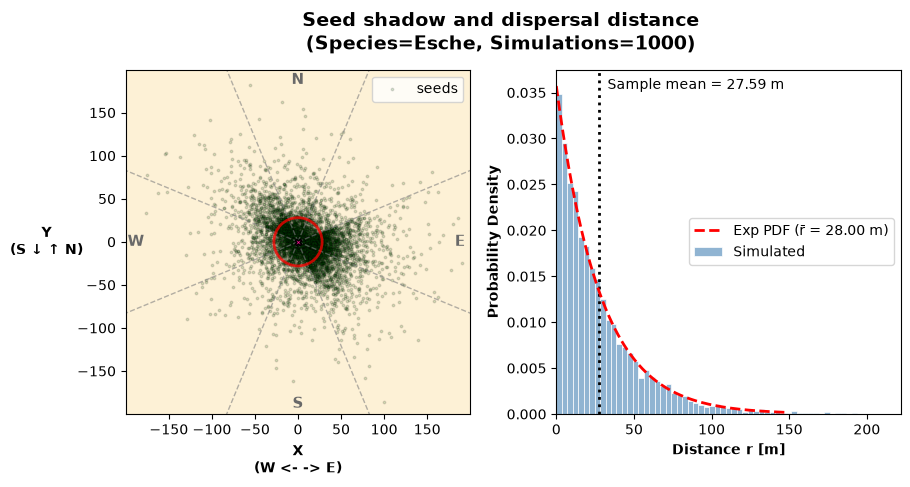

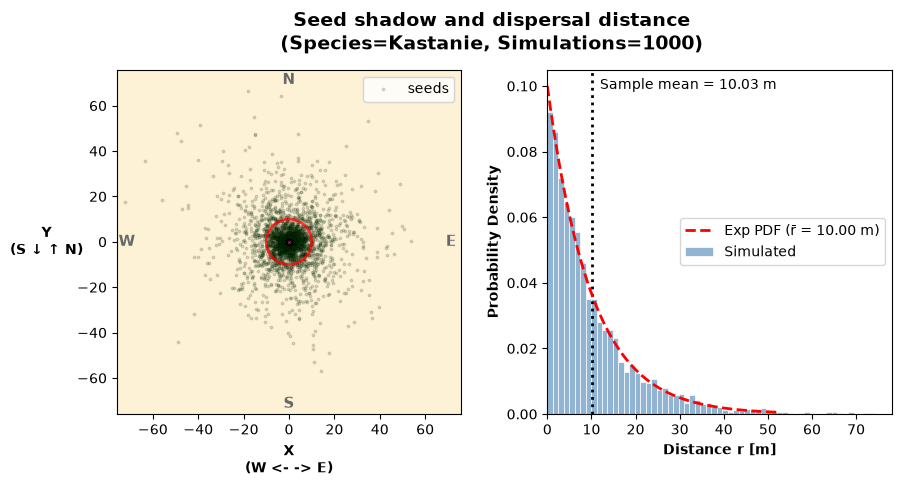

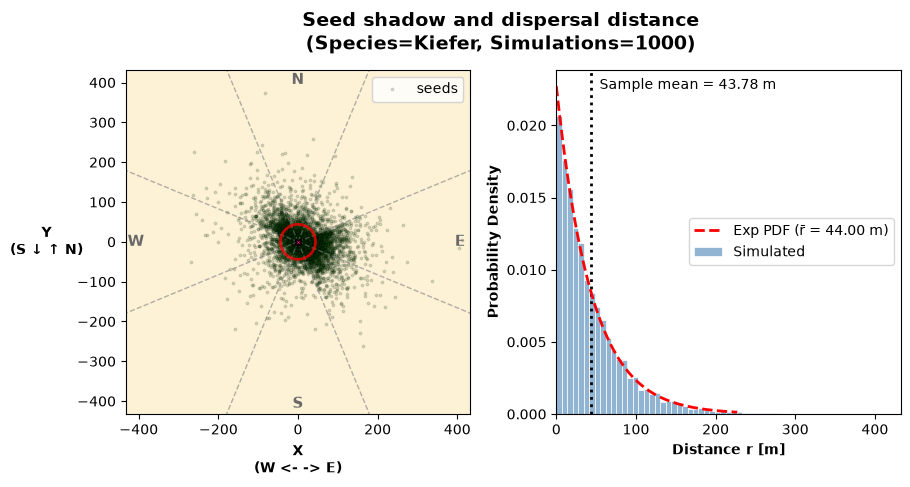

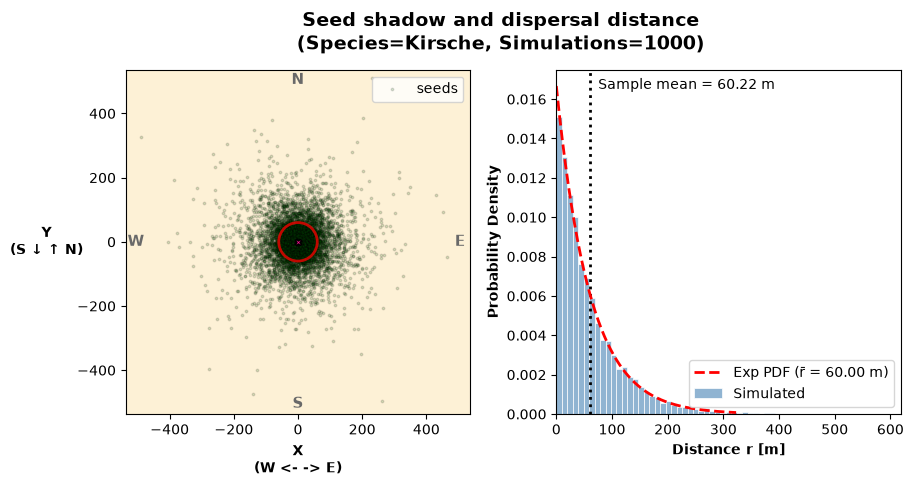

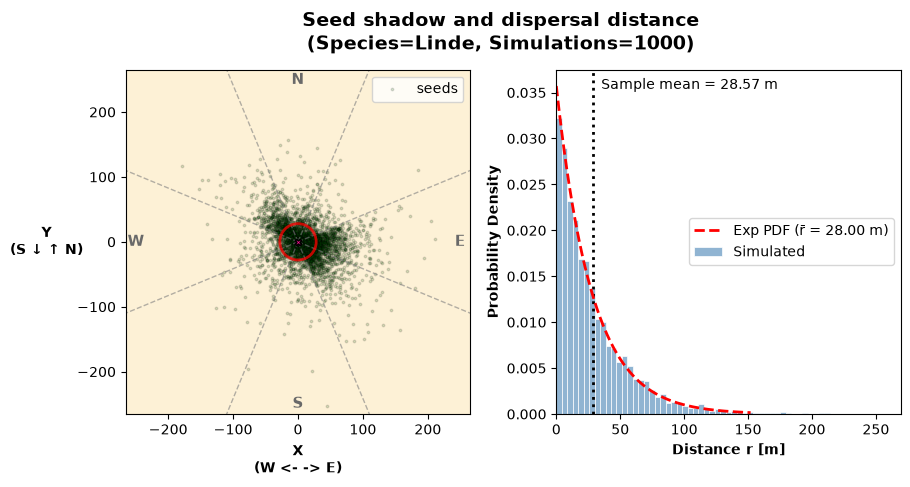

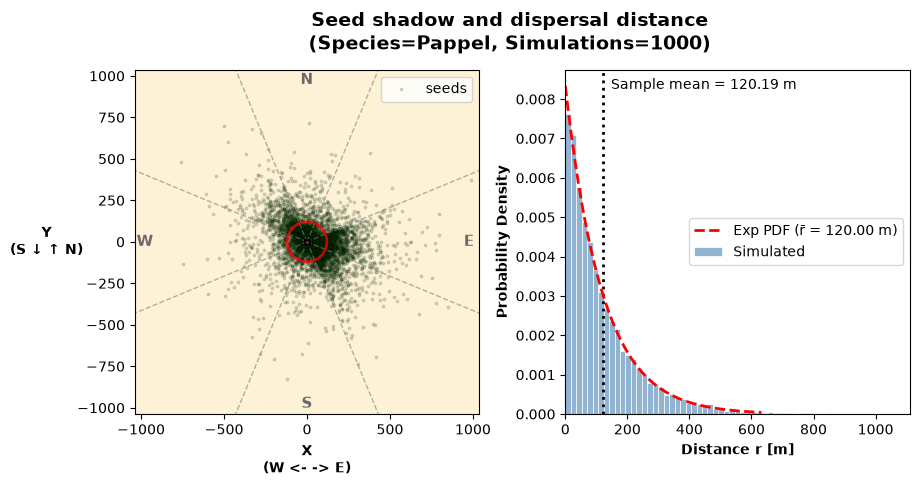

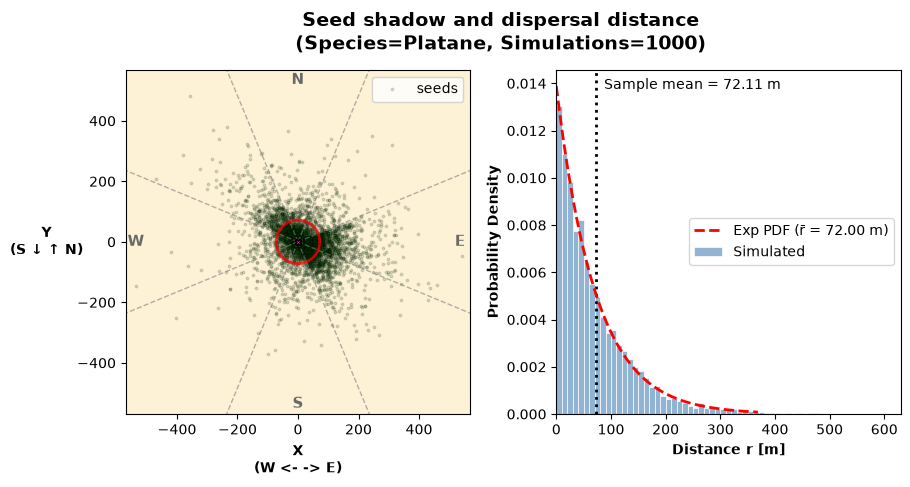

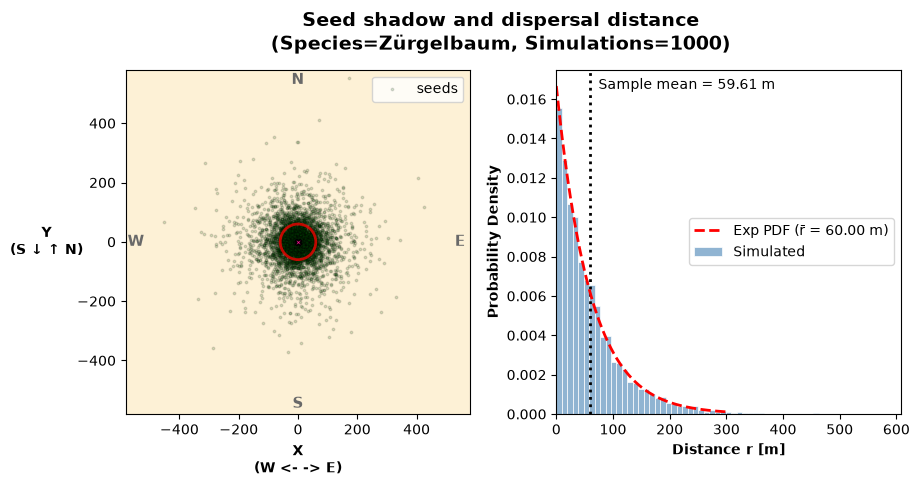

,species,dispersal,total_seeds,r_bar_theory_m,r_bar_sim_m,rel_error_pct,ks_pvalue
0,Ahorn,wind,8067,36.0,36.139,0.386,0.828
1,Akazie,gravity,11931,10.0,9.983,0.167,0.644
2,Buche,animal,4806,30.0,30.253,0.842,0.346
3,Esche,wind,9349,28.0,27.588,1.471,0.409
4,Kastanie,animal,3237,10.0,10.032,0.323,0.667
5,Kiefer,wind,8056,44.0,43.783,0.493,0.499
6,Kirsche,animal,9708,60.0,60.222,0.369,0.609
7,Linde,wind,6522,28.0,28.573,2.045,0.233
8,Pappel,wind,8097,120.0,120.187,0.156,0.577
9,Platane,wind,6368,72.0,72.108,0.150,0.380


In [25]:
HEIGHT_CLASS = 4      # Task 1: tree of height class k = 4
WIND_STRENGTH = 10    # default s from the assignment
NUM_INSTANCES = 1_000 # simulated years -> Poisson number of seeds each

env = EnvironmentState(wind_rose=DEFAULT_WIND_ROSE, wind_strength=WIND_STRENGTH)
rows = []
for cfg in species_config.values():
    params = SeedDispersalSimulationParams(
        config=cfg, environment_state=env, height_class=HEIGHT_CLASS, num_instances=NUM_INSTANCES
    )
    result = SeedDispersalSimulation(params, rng=rng).run()
    m = evaluate_seed_shadow(result)
    rows.append({
        "species": cfg.species_name,
        "dispersal": cfg.dispersal_type.value,
        "total_seeds": m.total_seeds,
        "r_bar_theory_m": m.theoretical_mean_radius,
        "r_bar_sim_m": m.empirical_mean_radius,
        "rel_error_pct": m.rel_error_pct,
        "ks_pvalue": m.ks_pvalue,
    })
    fig = plot_simulated_seed_shadow_and_distance_histogram(result=result, size=(10, 5))
    fig.savefig(f"docs/overleaf/images/seed_shadow_{cfg.species_name.replace('ü', 'ue')}.png",
            dpi=200, bbox_inches="tight")
    plt.show()

df_results = pd.DataFrame(rows).round(3)
df_results


In [16]:
species_config

{'Ahorn': SpeciesConfig(species_name='Ahorn', dispersal_type=<DispersalType.WIND: 'wind'>, wind_spreading_factor=0.9, mean_dispersal_distance=None, fecundity=2.0, maturity_age=20, years_per_height_class=12, maximal_height_class=8, mean_life_span=300, shade_tolerance=0.8),
 'Akazie': SpeciesConfig(species_name='Akazie', dispersal_type=<DispersalType.GRAVITY: 'gravity'>, wind_spreading_factor=None, mean_dispersal_distance=10.0, fecundity=3.0, maturity_age=6, years_per_height_class=7, maximal_height_class=7, mean_life_span=100, shade_tolerance=0.18),
 'Buche': SpeciesConfig(species_name='Buche', dispersal_type=<DispersalType.ANIMAL: 'animal'>, wind_spreading_factor=None, mean_dispersal_distance=30.0, fecundity=1.2, maturity_age=30, years_per_height_class=18, maximal_height_class=8, mean_life_span=400, shade_tolerance=0.89),
 'Esche': SpeciesConfig(species_name='Esche', dispersal_type=<DispersalType.WIND: 'wind'>, wind_spreading_factor=0.7, mean_dispersal_distance=None, fecundity=2.4, matu

In [17]:
import plotly.graph_objects as go

species_keys = list(species_config.keys())
species_objs = list(species_config.values())

fig = go.Figure(
    data=[
        go.Bar(
            x=species_keys,
            y=[obj.maturity_age for obj in species_objs],
            marker_color="brown",
            text=[obj.maturity_age for obj in species_objs],
            textposition="auto",
        )
    ]
)

#fig.update_layout(
#    title="Fecundity by Species",
#    xaxis_title="Species",
#    yaxis_title="Fecundity (φ)",
#    template="plotly_white",
#)

fig.show()